In [1]:
import pandas as pd

from fowt_ml.datasets import get_data, fix_column_names

import sys
sys.path.append("../")

from utils import plot_forces, compute_mi_scores

### Load the data in a dataframe

In [2]:
# create a data config
data_id = "exp1644"
cfg = {
  data_id: {
    "path_file": f"./hybridlabs/data_x_wp2_202512/dataB/decay_cl/{data_id}.mat",
    "aux_data": {"wind_speed": 0.0}
  }
}  # closed-lopp, surge case, no wind, no-rotation

In [3]:
df = get_data(data_id=data_id, config=cfg)
df.index = pd.to_timedelta(df.index*1e-3, unit='s')  # set time index 

In [4]:
print(len(df), df.columns)

48401 Index(['time', 'acc_calc6[0]', 'acc_calc6[1]', 'acc_calc6[2]', 'acc_calc6[3]',
       'acc_calc6[4]', 'acc_calc6[5]', 'acc_tb_meas3[0]', 'acc_tb_meas3[1]',
       'acc_tb_meas3[2]',
       ...
       'spd_rot_cmd', 'time_wave_precalc', 'tq_mot_act', 'trig_Hex_in',
       'trig_PIV_in', 'trig_PIV_out', 'wtm2_spd_rot_act', 'wtm2_spd_rot_cmd',
       'wtm2_tq_mot_act', 'wind_speed'],
      dtype='object', length=146)


#### Inspecting the data

In no-wind (wind speed is zero) and no-rotation (rotational speed is zero) conditions,
the measured forces are considered to be of inertial and gravitational origin only 
i.e. `F_meas = F_in + F_grav` and the aerodynamic forces (F_aero) are considered to be negligible (~0).
In physics-based method, `F_corr = F_in + F_grav` is calculated using acceleration. Then, `Faero_est = F_meas − F_corr`.

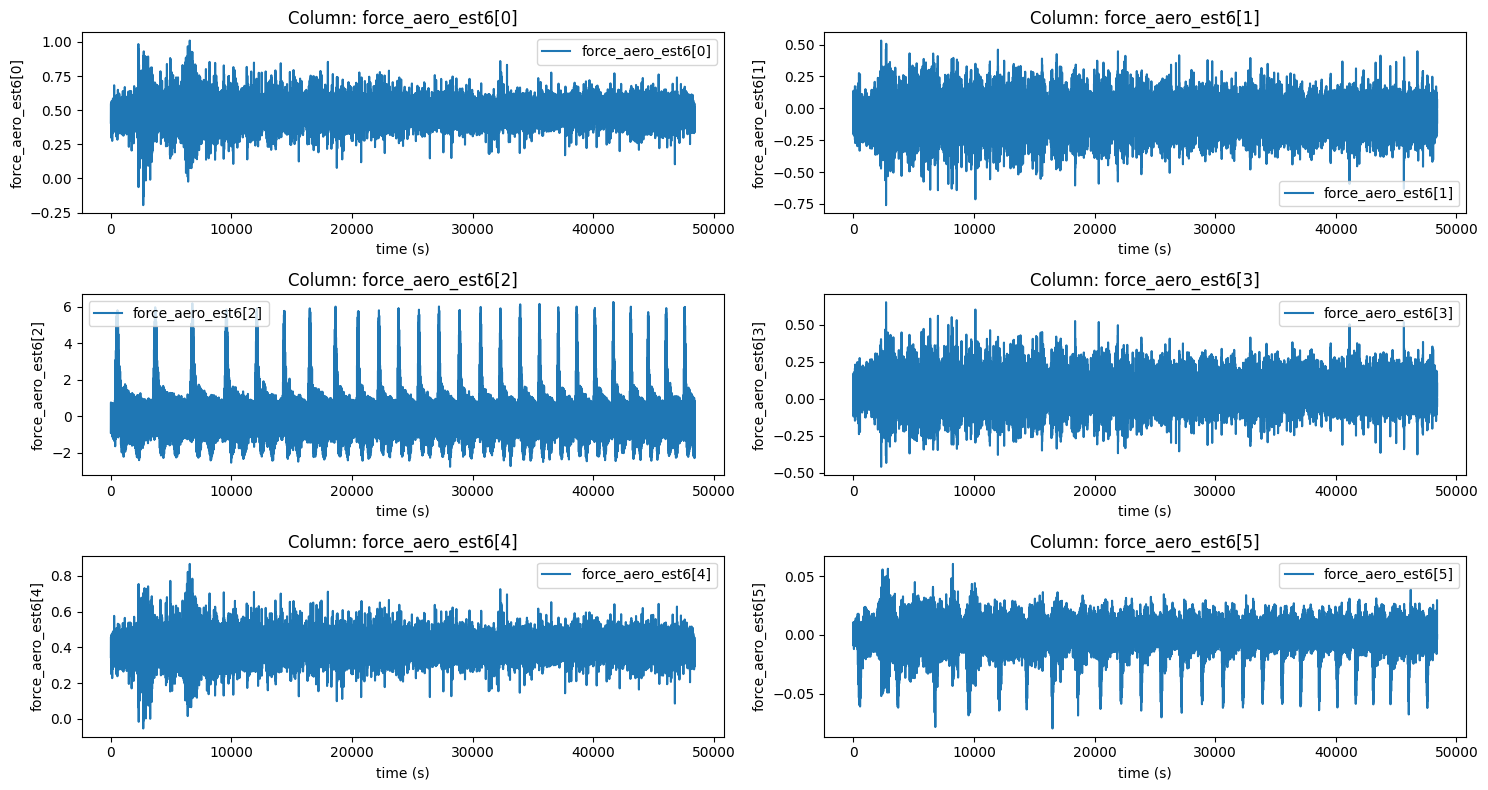

In [5]:
# Estimated aeordynamic force after applying the correction
force_aero_est =  [
      'force_aero_est6[0]',
      'force_aero_est6[1]',
      'force_aero_est6[2]',
      'force_aero_est6[3]',
      'force_aero_est6[4]',
      'force_aero_est6[5]',
      ]

plot_forces(df[force_aero_est])

#### Defining targets and features

We want to estimate the measured rotor forces from the measured acceleration and/or position
(POS). This would be equivalent to F_corr. The variables are:

- acceleration in xyz-direction measured at nacelle (acc_tt) and at tower base (acc_tb)
- rotor force in xyz-direction measured under the nacelle (force_tt)

In [6]:
# check the mutual info between targets and features
targets = [
    'force_tt_meas6[0]',
    'force_tt_meas6[1]',
    'force_tt_meas6[2]',
]

predictors = [
    'acc_tb_meas3[0]',
    'acc_tb_meas3[1]',
    'acc_tb_meas3[2]',
    'acc_tt_meas3[0]',
    'acc_tt_meas3[1]',
    'acc_tt_meas3[2]',
]

mi_scores = compute_mi_scores(df, targets, predictors)
mi_scores

,force_tt_meas6[0],force_tt_meas6[1],force_tt_meas6[2]
acc_tb_meas3[0],0.123829,0.029272,0.028420
acc_tb_meas3[1],0.045380,0.102488,0.013459
acc_tb_meas3[2],0.093242,0.016824,0.023748
acc_tt_meas3[0],1.038200,0.048226,0.059434
acc_tt_meas3[1],0.036009,0.801437,0.016318
acc_tt_meas3[2],0.034953,0.010824,0.008957
